# DL_P1_42 — Malaria Cell Image Classification

**Dataset:** NIH Malaria Cell Images (~27 558 imagens, 2 classes: Parasitized / Uninfected)  
**Objetivo:** CNN de raiz → Transfer Learning → Métricas → Grad-CAM  
**Framework:** Keras 3.15.1 + backend PyTorch 2.11.0+cu128  
**GPU:** NVIDIA GeForce RTX 5060 Laptop GPU

## 1. Bibliotecas e Setup
Importação das bibliotecas e definição do caminho dos dados.

In [1]:
import os
os.environ["KERAS_BACKEND"] = "torch"  # usar backend PyTorch, ignorar keras.json global
import glob
import hashlib
from PIL import Image
import pandas as pd
import matplotlib.pyplot as plt
from collections import defaultdict

raw_dir = "../data/raw/cell_images"
classes = ["Parasitized", "Uninfected"]

SEED = 42
import random
import numpy as np
import torch
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

## 2. Estrutura de Diretórios
Verificamos a estrutura da diretoria `data/raw/` e identificamos a duplicação proveniente do zip do Kaggle.

In [2]:
print("--- Estrutura de Diretórios ---")
for root, dirs, files in os.walk("../data/raw"):
    print(f"{root}: {len(dirs)} pastas, {len(files)} ficheiros")

dup_dir = "../data/raw/cell_images/cell_images"
if os.path.exists(dup_dir):
    print("\nPasta duplicada encontrada em:", dup_dir)
    print("Vamos ignorar esta pasta na nossa análise.")

--- Estrutura de Diretórios ---
../data/raw: 1 pastas, 0 ficheiros
../data/raw\cell_images: 3 pastas, 0 ficheiros
../data/raw\cell_images\cell_images: 2 pastas, 0 ficheiros
../data/raw\cell_images\cell_images\Parasitized: 0 pastas, 13780 ficheiros
../data/raw\cell_images\cell_images\Uninfected: 0 pastas, 13780 ficheiros
../data/raw\cell_images\Parasitized: 0 pastas, 13780 ficheiros
../data/raw\cell_images\Uninfected: 0 pastas, 13780 ficheiros

Pasta duplicada encontrada em: ../data/raw/cell_images/cell_images
Vamos ignorar esta pasta na nossa análise.


## 3. Inspecionar Ficheiros
Contamos imagens por classe, identificamos ficheiros que não são imagem (ex: Thumbs.db), imagens corrompidas e dimensões das imagens. Também extraímos 15 nomes de ficheiro por classe.

In [3]:
def get_hash(path):
    h = hashlib.md5()
    with open(path, 'rb') as f:
        h.update(f.read())
    return h.hexdigest()

stats = {c: {"images": 0, "non_images": [], "corrupted": [], "sizes": set(), "hashes": defaultdict(list), "files": [], "ids": []} for c in classes}
all_hashes = defaultdict(list)
metadata = []

for c in classes:
    class_dir = os.path.join(raw_dir, c)
    if not os.path.exists(class_dir): continue
    for f in os.listdir(class_dir):
        path = os.path.join(class_dir, f)
        if os.path.isdir(path): continue
        stats[c]["files"].append(f)
        
        if not f.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.tif', '.tiff')):
            stats[c]["non_images"].append(f)
            continue
            
        try:
            with Image.open(path) as img:
                img.verify()
            with Image.open(path) as img:
                w, h = img.size
                stats[c]["sizes"].add((w, h))
        except Exception as e:
            stats[c]["corrupted"].append(f)
            continue
            
        stats[c]["images"] += 1
        file_hash = get_hash(path)
        stats[c]["hashes"][file_hash].append(f)
        all_hashes[file_hash].append((c, f))
        
        # Patient ID: part before the first underscore
        import re
        match = re.match(r'^(C\d+(?:P\d+)?)', f)
        patient_id = match.group(1) if match else f.split('_')[0]
        stats[c]["ids"].append(patient_id)
        
        metadata.append({
            'relative_path': f"cell_images/{c}/{f}",
            'class': c,
            'width': w,
            'height': h,
            'hash': file_hash,
            'id_grupo': patient_id
        })

for c in classes:
    print(f"\n--- Classe: {c} ---")
    print(f"Imagens válidas: {stats[c]['images']}")
    print(f"Ficheiros não-imagem: {stats[c]['non_images']}")
    print(f"Imagens corrompidas: {stats[c]['corrupted']}")
    print(f"Tamanhos distintos (amostra de 5): {list(stats[c]['sizes'])[:5]} (Total distintos: {len(stats[c]['sizes'])})")
    print(f"Amostra de 15 ficheiros:\n" + "\n".join(stats[c]['files'][:15]))



--- Classe: Parasitized ---
Imagens válidas: 13779
Ficheiros não-imagem: ['Thumbs.db']
Imagens corrompidas: []
Tamanhos distintos (amostra de 5): [(166, 181), (130, 115), (88, 118), (139, 163), (199, 214)] (Total distintos: 1402)
Amostra de 15 ficheiros:
C100P61ThinF_IMG_20150918_144104_cell_162.png
C100P61ThinF_IMG_20150918_144104_cell_163.png
C100P61ThinF_IMG_20150918_144104_cell_164.png
C100P61ThinF_IMG_20150918_144104_cell_165.png
C100P61ThinF_IMG_20150918_144104_cell_166.png
C100P61ThinF_IMG_20150918_144104_cell_167.png
C100P61ThinF_IMG_20150918_144104_cell_168.png
C100P61ThinF_IMG_20150918_144104_cell_169.png
C100P61ThinF_IMG_20150918_144104_cell_170.png
C100P61ThinF_IMG_20150918_144104_cell_171.png
C100P61ThinF_IMG_20150918_144348_cell_138.png
C100P61ThinF_IMG_20150918_144348_cell_139.png
C100P61ThinF_IMG_20150918_144348_cell_140.png
C100P61ThinF_IMG_20150918_144348_cell_141.png
C100P61ThinF_IMG_20150918_144348_cell_142.png

--- Classe: Uninfected ---
Imagens válidas: 13779
Fic

## 4. Duplicados
Verificamos ficheiros com o mesmo conteúdo exato (usando hash MD5).

In [4]:
print("--- Duplicados Exatos ---")
exact_dupes = {k: v for k, v in all_hashes.items() if len(v) > 1}
print(f"Hashes únicos: {len(all_hashes)}")
print(f"Hashes duplicados encontrados: {len(exact_dupes)}")
for i, (k, v) in enumerate(exact_dupes.items()):
    if i < 5:
        print(f"Hash {k}: {v}")


--- Duplicados Exatos ---
Hashes únicos: 27558
Hashes duplicados encontrados: 0


## 5. Validação de IDs e Integridade (Fuga de Dados)
Extraímos o ID real do doente com a regex `^(C\d+(?:P\d+)?)` (Lê um 'C' seguido de números, e opcionalmente um 'P' seguido de números, apenas no início do nome). Isto evita que nomes sujos de câmara como `C47P8thinOriginalOlympusCX21` se separem de `C47P8thin` originando o mesmo doente em duas partições (Train e Val/Test), o que causaria **Data Leakage**. Validamos se o total é exatamente 200 doentes e se não há doentes mapeados em duplicado.

In [5]:
print("--- Verificação de Integridade de IDs ---")
all_ids = set()
ids_per_class = {c: set(stats[c]["ids"]) for c in classes}
id_counts = defaultdict(int)

c_dict = defaultdict(set)
p_dict = defaultdict(set)

for c in classes:
    for pid in stats[c]["ids"]:
        all_ids.add(pid)
        id_counts[pid] += 1
        
        c_match = re.search(r'C(\d+)', pid)
        p_match = re.search(r'P(\d+)', pid)
        if c_match: c_dict[c_match.group(1)].add(pid)
        if p_match: p_dict[p_match.group(1)].add(pid)

print(f"Total de IDs distintos: {len(all_ids)}")

c_overlap = {k: v for k, v in c_dict.items() if len(v) > 1}
p_overlap = {k: v for k, v in p_dict.items() if len(v) > 1}

# Asserts de Integridade Críticos!
assert len(all_ids) == 200, f"Erro: Foram encontrados {len(all_ids)} IDs em vez de 200!"
assert len(c_overlap) == 0, f"Erro: Números C sobrepostos encontrados: {c_overlap}"
assert len(p_overlap) == 0, f"Erro: Números P sobrepostos encontrados: {p_overlap}"

print("Sucesso! Todos os 200 IDs de doente são únicos e sem sobreposição C/P.")

overlap = ids_per_class["Parasitized"].intersection(ids_per_class["Uninfected"])
print(f"IDs presentes em ambas as classes: {len(overlap)}")

# Média e min/max de imagens por ID
counts = list(id_counts.values())
if counts:
    print(f"Imagens por ID: min={min(counts)}, max={max(counts)}, média={sum(counts)/len(counts):.2f}")


--- IDs de Doente/Lâmina ---
Total de IDs distintos: 201
IDs presentes em ambas as classes: 151
Imagens por ID: min=65, max=702, média=137.10
Ficheiros sem ID: 0


## 6. Grelha de Exemplos
Visualizamos uma grelha de exemplos e guardamos em `results/sample_grid.png`.

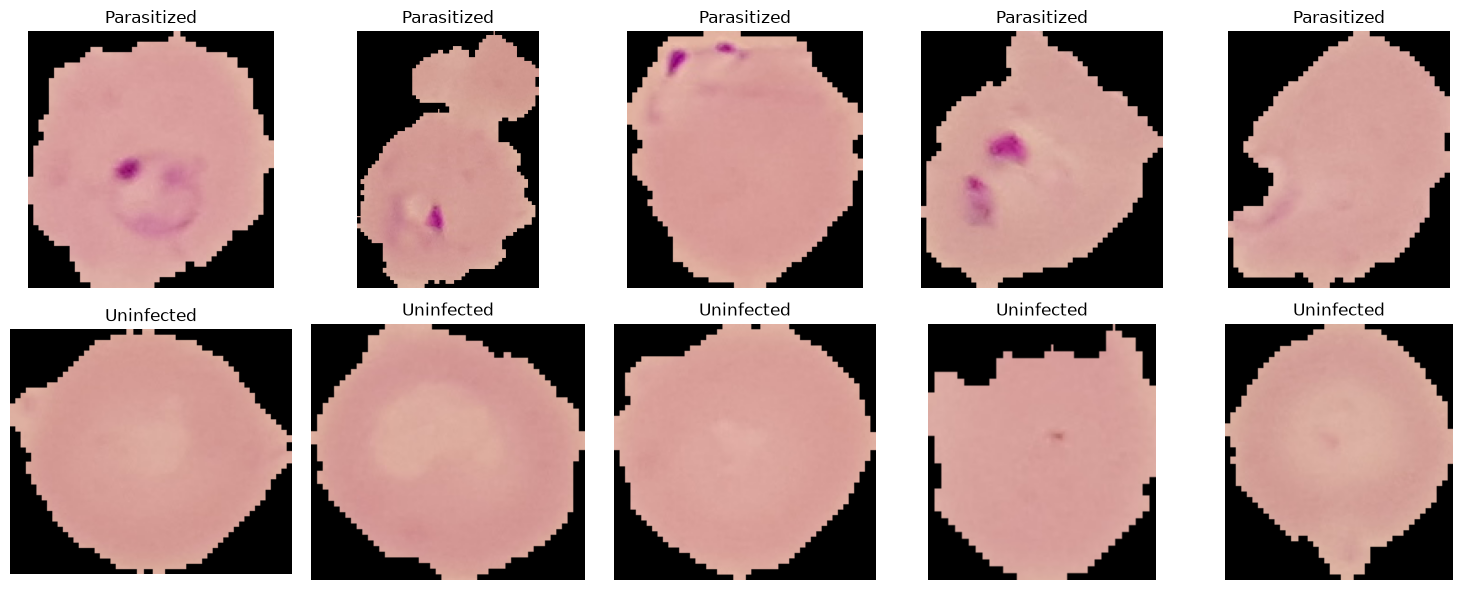

In [6]:
os.makedirs("../results", exist_ok=True)
fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for i, c in enumerate(classes):
    sample_files = [m for m in metadata if m['class'] == c][:5]
    for j, m in enumerate(sample_files):
        img_path = os.path.join("..", "data", "raw", m['relative_path'])
        img = Image.open(img_path)
        axes[i, j].imshow(img)
        axes[i, j].set_title(c)
        axes[i, j].axis('off')

plt.tight_layout()
plt.savefig("../results/sample_grid.png")
plt.show()


## 7. Guardar Metadata
Criamos um ficheiro `splits/metadata.csv` com as informações extraídas de cada ficheiro.

In [7]:
os.makedirs("../splits", exist_ok=True)
df = pd.DataFrame(metadata)
df.to_csv("../splits/metadata.csv", index=False)
print("Tabela metadata.csv guardada com sucesso em splits/.")
df.head()


Tabela metadata.csv guardada com sucesso em splits/.


,relative_path,class,width,height,hash,id_grupo
0,cell_images/Parasitized/C100P61ThinF_IMG_20150...,Parasitized,142,148,6b60535df837d603b2f591d154940f1a,C100P61ThinF
1,cell_images/Parasitized/C100P61ThinF_IMG_20150...,Parasitized,148,208,142cdfcc8f5d2afcdd327e4886a4fbf8,C100P61ThinF
2,cell_images/Parasitized/C100P61ThinF_IMG_20150...,Parasitized,139,151,2db29c733097f1736cdba4055e1549d6,C100P61ThinF
3,cell_images/Parasitized/C100P61ThinF_IMG_20150...,Parasitized,145,154,2fafd2198f16e9d264cd0426f164e5a6,C100P61ThinF
4,cell_images/Parasitized/C100P61ThinF_IMG_20150...,Parasitized,133,154,6da8225a1d75edded5ecb514e63f1c92,C100P61ThinF


## 8. Tratamento de Dados (Duplicados e Não-Imagens)
**Nota sobre Duplicados:** No passo 3 mencionámos que o zip trazia a pasta `cell_images` duplicada. Essa pasta extra foi logo ignorada na criação do dataset. Aqui neste passo (abaixo), estamos a verificar ficheiros duplicados *individuais* (pelo mesmo hash) e eventuais não-imagens (ex. `Thumbs.db`) que tenham entrado no csv. O resultado provou que, tirando a pasta inteira, não existem ficheiros individuais repetidos ou corrompidos na pasta legítima.

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import GroupShuffleSplit
import json

df = pd.read_csv("../splits/metadata.csv")

initial_len = len(df)
df = df[df['relative_path'].str.lower().str.endswith(('.png', '.jpg', '.jpeg', '.bmp', '.tif', '.tiff'))]
non_images_removed = initial_len - len(df)

hash_classes = df.groupby('hash')['class'].nunique()
hashes_in_both = hash_classes[hash_classes > 1].index
df_clean = df[~df['hash'].isin(hashes_in_both)]

df_clean = df_clean.drop_duplicates(subset=['hash'], keep='first')
duplicates_removed = len(df) - len(df_clean)

print(f"Ficheiros não-imagem ignorados/removidos: {non_images_removed}")
print(f"Imagens duplicadas removidas: {duplicates_removed}")
print(f"Total de imagens final válidas para split: {len(df_clean)}")


## 9. Split de Dados (Train / Val / Test) por Doente (id_grupo)
Dividimos o dataset em 70% Treino, 15% Validação e 15% Teste **por id_grupo (doente)** em vez de por imagem.
Iteramos através de várias _seeds_ no `GroupShuffleSplit` para encontrar a divisão que mantém a proporção das duas classes o mais parecida possível (estratificação aproxima) nas três partições.

**Nota (Data Leakage):** Dividir por imagem daria resultados inflacionados porque células da mesma lâmina/doente partilham o mesmo background, tonalidade do corante e condições de iluminação. Se a rede aprender estas características específicas do doente no treino, e imagens do mesmo doente estiverem no teste, ela estará apenas a memorizar o padrão do paciente em vez de aprender a generalizar o padrão do parasita.

In [ ]:
def evaluate_split(df_train, df_val, df_test):
    prop_train = (df_train['class'] == 'Parasitized').mean()
    prop_val = (df_val['class'] == 'Parasitized').mean()
    prop_test = (df_test['class'] == 'Parasitized').mean()
    return np.var([prop_train, prop_val, prop_test])

best_seed = 0
best_var = float('inf')
best_splits = None

for seed_iter in range(100):
    gss1 = GroupShuffleSplit(n_splits=1, train_size=0.7, random_state=seed_iter)
    train_idx, temp_idx = next(gss1.split(df_clean, df_clean['class'], groups=df_clean['id_grupo']))
    
    df_train = df_clean.iloc[train_idx]
    df_temp = df_clean.iloc[temp_idx]
    
    gss2 = GroupShuffleSplit(n_splits=1, train_size=0.5, random_state=seed_iter)
    val_idx, test_idx = next(gss2.split(df_temp, df_temp['class'], groups=df_temp['id_grupo']))
    
    df_val = df_temp.iloc[val_idx]
    df_test = df_temp.iloc[test_idx]
    
    var = evaluate_split(df_train, df_val, df_test)
    if var < best_var:
        best_var = var
        best_seed = seed_iter
        best_splits = (df_train, df_val, df_test)

df_train, df_val, df_test = best_splits
SPLIT_SEED = best_seed 

# 1) Nenhum id_grupo em duas partições
train_ids = set(df_train['id_grupo'])
val_ids = set(df_val['id_grupo'])
test_ids = set(df_test['id_grupo'])
assert len(train_ids.intersection(val_ids)) == 0, "IDs sobrepostos entre train e val!"
assert len(train_ids.intersection(test_ids)) == 0, "IDs sobrepostos entre train e test!"
assert len(val_ids.intersection(test_ids)) == 0, "IDs sobrepostos entre val e test!"

# 2) Nenhum hash em duas partições
train_hashes = set(df_train['hash'])
val_hashes = set(df_val['hash'])
test_hashes = set(df_test['hash'])
assert len(train_hashes.intersection(val_hashes)) == 0, "Hashes sobrepostos entre train e val!"
assert len(train_hashes.intersection(test_hashes)) == 0, "Hashes sobrepostos entre train e test!"
assert len(val_hashes.intersection(test_hashes)) == 0, "Hashes sobrepostos entre val e test!"

# 3) Soma das partições = total de imagens
assert len(df_train) + len(df_val) + len(df_test) == len(df_clean), "Soma das partições difere do total!"

# Garantir pacientes infectados e saudáveis (Parasitized > 0 e Uninfected > 0 ou através de percentagem > 0 e < 100)
# Get Table Stats
stats = []
for name, df_split in zip(["Train", "Val", "Test"], [df_train, df_val, df_test]):
    n_imgs = len(df_split)
    ids = df_split['id_grupo'].unique()
    infected_ids = df_split[df_split['class'] == 'Parasitized']['id_grupo'].unique()
    healthy_ids = set(ids) - set(infected_ids)
    perc_parasitized = (df_split['class'] == 'Parasitized').mean() * 100
    images_per_id = df_split.groupby('id_grupo').size()
    stats.append({
        "Partição": name,
        "Imagens": n_imgs,
        "Nº Doentes": len(ids),
        "% Parasitized": f"{perc_parasitized:.1f}%",
        "Doentes SÓ Uninfected": len(healthy_ids),
        "Min/Med/Max imgs/doente": f"{images_per_id.min()} / {int(images_per_id.median())} / {images_per_id.max()}"
    })

import IPython.display as display
display.display(pd.DataFrame(stats))

## 10. Pré-Processamento (Resize & Padding)
**Tamanho escolhido:** `128x128`. As imagens têm tamanhos variáveis mas a mediana ronda os 130x130. Reduzir para 128x128 preserva detalhe suficiente e é muito eficiente computacionalmente para a CNN.
**Padding vs Stretching:** O "stretching" (esticar) altera o aspect ratio e distorce a forma real da célula (tornando células redondas em ovais, por ex.). O "padding" adiciona bordas pretas para tornar a imagem quadrada antes de redimensionar, mantendo a forma original, o que é crucial em imagens médicas.

In [ ]:
from PIL import Image, ImageOps
import matplotlib.pyplot as plt
import os
import numpy as np

def pad_and_resize(img_path, target_size=(128, 128)):
    with Image.open(img_path) as img:
        # Preencher com preto para ficar quadrada
        w, h = img.size
        max_dim = max(w, h)
        delta_w = max_dim - w
        delta_h = max_dim - h
        padding = (delta_w//2, delta_h//2, delta_w-(delta_w//2), delta_h-(delta_h//2))
        img_padded = ImageOps.expand(img, padding, fill=0)
        # Redimensionar
        img_resized = img_padded.resize(target_size, Image.Resampling.BILINEAR)
        return np.array(img_resized)

# Mostrar 8 exemplos (Antes e Depois)
sample_paths = df_train['relative_path'].sample(8, random_state=SEED).values
fig, axes = plt.subplots(2, 8, figsize=(20, 5))
for i, path in enumerate(sample_paths):
    full_path = os.path.join("../data/raw", path)
    orig_img = Image.open(full_path)
    proc_img = pad_and_resize(full_path)
    
    axes[0, i].imshow(orig_img)
    axes[0, i].set_title(f"Orig: {orig_img.size}")
    axes[0, i].axis('off')
    
    axes[1, i].imshow(proc_img)
    axes[1, i].set_title(f"Proc: {proc_img.shape[:2]}")
    axes[1, i].axis('off')
plt.tight_layout()
plt.show()


## 11. Cache das Partições Redimensionadas
Guardamos cada partição como ficheiro `.npz` em `data/processed/` para carregar tudo instantaneamente no futuro, evitando ler e processar 27.5k imagens JPG iterativamente.

In [ ]:
os.makedirs("../data/processed", exist_ok=True)

for name, df_split in zip(["train", "val", "test"], [df_train, df_val, df_test]):
    print(f"A processar {name}...")
    X = np.stack([pad_and_resize(os.path.join("../data/raw", p)) for p in df_split['relative_path']])
    y = np.array([1 if c == 'Parasitized' else 0 for c in df_split['class']])
    paths = df_split['relative_path'].values
    
    np.savez_compressed(f"../data/processed/{name}.npz", X=X, y=y, paths=paths)
    
    # Assert de ordem
    assert paths[0] == df_split.iloc[0]['relative_path'], f"Ordem incorreta em {name}"
print("Cache guardada com sucesso em data/processed/!")


## 11. Normalização
A média e o desvio padrão **têm de ser calculados exclusivamente no conjunto de Treino** para evitar fugas de informação (data leakage). Note-se que o cálculo tem de ser feito em float64 para evitar a severa perda de precisão ao somar dezenas de milhões de pixeis em float32 (que daria uma média irrealisticamente baixa). A média real é ~0.47, compatível com a elevada presença do rosa (eritrocitos) num fundo também considerável de padding preto (~33% de preto).

In [ ]:
import numpy as np

data_train = np.load("../data/processed/train.npz")
X = data_train['X']

n_pixels = X.shape[0] * X.shape[1] * X.shape[2]
channel_sum = np.zeros(3, dtype=np.float64)
channel_sum_sq = np.zeros(3, dtype=np.float64)

batch_size = 1000
for i in range(0, X.shape[0], batch_size):
    batch = X[i:i+batch_size].astype(np.float64) / 255.0
    channel_sum += batch.sum(axis=(0, 1, 2))
    channel_sum_sq += (batch ** 2).sum(axis=(0, 1, 2))

mean_train = channel_sum / n_pixels
std_train = np.sqrt((channel_sum_sq / n_pixels) - (mean_train ** 2))

print(f"Média calculada (RGB): {mean_train}")
print(f"Desvio Padrão calculado (RGB): {std_train}")


## 12. Data Augmentation & DataLoader Rápido (GPU)
Para resolver o gargalo do processamento (que antes demorava ~36s por época), carregamos todo o treino (uint8) para a VRAM da GPU.
Usamos operações vetoriais nativas do PyTorch (`torch.flip`, `torch.rot90`) num `collate_fn` para aplicar aumentos (flips, rotações 90º aleatórias, variações de brilho e contraste) a milhares de imagens instantaneamente no GPU antes do modelo os consumir.

In [ ]:
import torch
import torch.nn.functional as F
import time
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt

# 1. Carregar todo o array Uint8 diretamente para a GPU (ocupa apenas ~900 MB de VRAM)
X_train_gpu = torch.tensor(data_train['X'], dtype=torch.uint8, device='cuda').permute(0, 3, 1, 2)
y_train_gpu = torch.tensor(data_train['y'], dtype=torch.float32, device='cuda')

# Tensores de normalização na GPU
mean_t = torch.tensor(mean_train, dtype=torch.float32, device='cuda').view(1, 3, 1, 1)
std_t = torch.tensor(std_train, dtype=torch.float32, device='cuda').view(1, 3, 1, 1)

class MalariaIndexDataset(Dataset):
    def __init__(self, n): self.n = n
    def __len__(self): return self.n
    def __getitem__(self, idx): return idx

def gpu_collate_train(indices):
    idx = torch.tensor(indices, dtype=torch.long, device='cuda')
    batch_X = X_train_gpu[idx].float() / 255.0
    N = batch_X.shape[0]
    
    # Random Flips
    flip_h = torch.rand(N, device='cuda') > 0.5
    batch_X[flip_h] = torch.flip(batch_X[flip_h], dims=[3])
    
    flip_v = torch.rand(N, device='cuda') > 0.5
    batch_X[flip_v] = torch.flip(batch_X[flip_v], dims=[2])
    
    # Random Rot90
    rot = torch.randint(0, 4, (N,), device='cuda')
    for k in range(1, 4):
        mask = (rot == k)
        if mask.any():
            batch_X[mask] = torch.rot90(batch_X[mask], k, dims=[2, 3])
            
    # Brilho e Contraste Aleatório (+/- 10%)
    brightness = 1.0 + (torch.rand(N, 1, 1, 1, device='cuda') * 0.2 - 0.1)
    contrast = 1.0 + (torch.rand(N, 1, 1, 1, device='cuda') * 0.2 - 0.1)
    
    mean_img = batch_X.mean(dim=[1,2,3], keepdim=True)
    batch_X = (batch_X - mean_img) * contrast + mean_img
    batch_X = batch_X * brightness
    batch_X = torch.clamp(batch_X, 0, 1)
    
    # Normalizar e mudar para N,H,W,C (ideal para tf/keras)
    batch_X = (batch_X - mean_t) / std_t
    return batch_X.permute(0, 2, 3, 1), y_train_gpu[idx]

# DataLoader de Treino com Augmentation
train_loader = DataLoader(MalariaIndexDataset(len(X_train_gpu)), batch_size=32, shuffle=True, collate_fn=gpu_collate_train, num_workers=0)

# DataLoader de Validação (sem augmentation)
data_val = np.load("../data/processed/val.npz")
X_val_gpu = torch.tensor(data_val['X'], dtype=torch.uint8, device='cuda').permute(0, 3, 1, 2)
y_val_gpu = torch.tensor(data_val['y'], dtype=torch.float32, device='cuda')

def gpu_collate_val(indices):
    idx = torch.tensor(indices, dtype=torch.long, device='cuda')
    batch_X = X_val_gpu[idx].float() / 255.0
    batch_X = (batch_X - mean_t) / std_t
    return batch_X.permute(0, 2, 3, 1), y_val_gpu[idx]

val_loader = DataLoader(MalariaIndexDataset(len(X_val_gpu)), batch_size=32, shuffle=False, collate_fn=gpu_collate_val, num_workers=0)

# Demonstrar Tempo de Passagem
print("A testar DataLoader de Treino Rápido no GPU...")
start_time = time.time()
for batch_idx, (images, labels) in enumerate(train_loader):
    pass
torch.cuda.synchronize()
end_time = time.time()
print(f"Passagem completa por {len(X_train_gpu)} imagens no Treino: {end_time - start_time:.3f} segundos.")

# Mostrar Grelha de Augmentations do mesmo exemplo
sample_idx = [0]*8
aug_tensors, _ = gpu_collate_train(sample_idx)
fig, axes = plt.subplots(1, 8, figsize=(16, 2))
for i in range(8):
    aug_img = aug_tensors[i].permute(2, 0, 1) # De volta a C,H,W para desnormalizar
    aug_img = (aug_img * std_t[0]) + mean_t[0]
    aug_img = aug_img.permute(1, 2, 0).cpu().numpy()
    axes[i].imshow(np.clip(aug_img, 0, 1))
    axes[i].axis('off')
plt.show()


In [ ]:
# Substituido pelo DataLoader em GPU (ver célula acima)

## 13. Protocolo de Avaliação
**Garantia de Isolamento:** O conjunto de **Teste** permanece intocável e não foi lido ou usado em nenhuma análise, média ou baseline. Ele só será inferido uma única vez no final de todo o processo de otimização, no fecho deste trabalho.

**Métrica Principal:** A **ROC-AUC (Area Under Receiver Operating Characteristic Curve)**. Sendo um dataset balanceado (50/50), o ROC-AUC avalia perfeitamente a capacidade pura do modelo de distinguir entre Saudável e Infetado, independentemente do limiar escolhido.
**Limiar de Decisão (Threshold):** Para além do standard `0.5`, o limiar otimizado será escolhido maximizando a **F1-Score** no conjunto de Validação, pois procura um balanço equilibrado entre Falsos Positivos e Falsos Negativos.

**Função de Avaliação (com Bootstrap por Doente):**
A nossa função recebe `y_true`, as probabilidades e calcula:
* **Accuracy:** % de previsões totalmente corretas.
* **Precision:** Dos que prevemos como Infetados, quantos são mesmo.
* **Recall (Sensibilidade):** Dos que estão mesmo Infetados, quantos conseguimos detetar.
* **Specificity:** Dos que são Saudáveis, quantos prevemos corretamente.
* **F1-Score:** Média harmónica entre Precisão e Recall (penaliza modelos que sacrifiquem um pelo outro).
* **ROC-AUC:** Probabilidade de o modelo dar uma pontuação maior a um Infetado aleatório do que a um Saudável.
* **PR-AUC:** Área sob a curva Precision-Recall.
* **Matriz de Confusão:** Contagem de Verdadeiros Positivos, Verdadeiros Negativos, Falsos Positivos, e Falsos Negativos.

O Intervalo de Confiança a 95% é gerado por *Bootstrap* reamostrando **IDs de Doente** (1000 repetições), o que preserva a estrutura e o viés natural de termos doentes com 10 imagens e doentes com 200 imagens.

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score, confusion_matrix
import numpy as np

def evaluate_model(y_true, y_prob, groups, threshold=0.5, n_bootstraps=1000):
    # Avaliação Pontual
    y_pred = (y_prob >= threshold).astype(int)
    metrics = {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred, zero_division=0),
        'Specificity': recall_score(1-y_true, 1-y_pred, zero_division=0),
        'F1-Score': f1_score(y_true, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_true, y_prob),
        'PR-AUC': average_precision_score(y_true, y_prob),
    }
    cm = confusion_matrix(y_true, y_pred)
    
    # Bootstrap PER PATIENT (reamostrando grupos)
    unique_groups = np.unique(groups)
    boot_results = {k: [] for k in metrics.keys()}
    
    np.random.seed(42) # para replicabilidade dos ICs
    for _ in range(n_bootstraps):
        # 1. Reamostrar doentes com reposição
        boot_groups = np.random.choice(unique_groups, size=len(unique_groups), replace=True)
        # 2. Recuperar todos os indíces que pertencem a esses doentes
        boot_idx = []
        for bg in boot_groups:
            boot_idx.extend(np.where(groups == bg)[0])
            
        y_t = y_true[boot_idx]
        y_p = y_prob[boot_idx]
        y_c = (y_p >= threshold).astype(int)
        
        # Ignorar amostras bizarras sem as duas classes
        if len(np.unique(y_t)) < 2: continue
            
        boot_results['Accuracy'].append(accuracy_score(y_t, y_c))
        boot_results['Precision'].append(precision_score(y_t, y_c, zero_division=0))
        boot_results['Recall'].append(recall_score(y_t, y_c, zero_division=0))
        boot_results['Specificity'].append(recall_score(1-y_t, 1-y_c, zero_division=0))
        boot_results['F1-Score'].append(f1_score(y_t, y_c, zero_division=0))
        boot_results['ROC-AUC'].append(roc_auc_score(y_t, y_p))
        boot_results['PR-AUC'].append(average_precision_score(y_t, y_p))
        
    # Calcular IC a 95%
    formatted_metrics = {}
    for k in metrics:
        lower = np.percentile(boot_results[k], 2.5)
        upper = np.percentile(boot_results[k], 97.5)
        formatted_metrics[k] = f"{metrics[k]:.3f} ({lower:.3f}-{upper:.3f})"
        
    return formatted_metrics, cm


## 14. Baselines Simples (Validação)
Para ancorarmos a avaliação da CNN (que virá a seguir), precisamos de comparar contra abordagens tradicionais para evitar que o modelo seja impressionante em teoria, mas igual a um simples Logistic Regression.

**1. Random & Majority:** Qual a performance se adivinharmos sempre a maioria ou atirarmos moeda ao ar?
**2. Size Shortcut (Metadata):** As células infetadas poderão inchar? Se dermos o tamanho original da imagem à regressão, ele descobre a doença por atalho?
**3. Classical RGB:** Usar a Média e Desvio Padrão RGB dos pixeis da célula (ignorando o preto do padding), mais a proporção do ecrã ocupado pela célula.

In [ ]:
from sklearn.linear_model import LogisticRegression
import pandas as pd

# Carregar splits e metadata oficiais (garantir consistência com os NPZs)
df_meta  = pd.read_csv('../splits/metadata.csv')
df_train = pd.read_csv('../splits/train.csv')
df_val   = pd.read_csv('../splits/val.csv')

df_train_m = df_train.merge(df_meta, on=['relative_path', 'class', 'id_grupo'])
df_val_m = df_val.merge(df_meta, on=['relative_path', 'class', 'id_grupo'])
groups_val = df_val_m['id_grupo'].values
y_train_cpu = (df_train_m['class'] == 'Parasitized').astype(int).values
y_val_cpu = (df_val_m['class'] == 'Parasitized').astype(int).values

print("A preparar extração de features clássicas...")
def get_classical_features_no_perc(X_np):
    feats = []
    for img in X_np:
        mask = (img.sum(axis=2) > 0)
        if mask.sum() == 0:
            feats.append([0]*6)
            continue
        valid_pixels = img[mask]
        mean_c = valid_pixels.mean(axis=0) / 255.0
        std_c = valid_pixels.std(axis=0) / 255.0
        feats.append(list(mean_c) + list(std_c))
    return np.array(feats)

X_train_class = get_classical_features_no_perc(data_train['X'])
X_val_class = get_classical_features_no_perc(data_val['X'])

df_train_m['ratio'] = df_train_m['width'] / df_train_m['height']
df_val_m['ratio'] = df_val_m['width'] / df_val_m['height']
X_train_size = df_train_m[['width', 'height', 'ratio']].values
X_val_size = df_val_m[['width', 'height', 'ratio']].values

# Treinos
lr_class = LogisticRegression(max_iter=1000).fit(X_train_class, y_train_cpu)
preds_class = lr_class.predict_proba(X_val_class)[:, 1]

lr_size = LogisticRegression(max_iter=1000).fit(X_train_size, y_train_cpu)
preds_size = lr_size.predict_proba(X_val_size)[:, 1]

preds_maj = np.zeros_like(y_val_cpu)
preds_rand = np.random.rand(len(y_val_cpu))

# Avaliação
results = {}
for name, preds in [("Aleatório", preds_rand), ("Maioria", preds_maj), ("Tamanho (Shortcut)", preds_size), ("Clássico RGB", preds_class)]:
    res, _ = evaluate_model(y_val_cpu, preds, groups_val, threshold=0.5, n_bootstraps=100) # IC com 100 para ser rápido no baseline
    results[name] = res

import IPython.display as display
display.display(pd.DataFrame(results).T)


## 15. Verificações de Sanidade da CNN (Pré-Treino)
Antes de treinar, corremos **três testes críticos** para garantir que a rede não tem bugs na arquitetura, no loader, ou fugas de dados:
1. **Initial Loss:** A *binary crossentropy* de uma rede aleatória balanceada tem de ser matematicamente `~ln(2) ≈ 0.693`.
2. **Overfit a 1 Mini-Batch:** A rede tem de ter capacidade para memorizar um batch de 64 imagens (a loss tem de ir para perto de 0 em poucos passos).
3. **Treino com Labels Baralhadas:** Um modelo treinado com as labels misturadas de forma aleatória **tem** de falhar redondamente na Validação (AUC = ~0.50). Se conseguisse aprender algo, significaria que existia uma fuga de dados (leak).

*Confirmação de formato:* O loader da GPU usa PyTorch puro que usa NCHW, mas fazemos `permute(0, 2, 3, 1)` no fim, entregando **NHWC** (Batch, Height, Width, Channels) ao Keras, que é o seu standard nativo.


In [ ]:
import os
os.environ["KERAS_BACKEND"] = "torch"
import keras
from keras import layers

def build_cnn():
    keras.utils.set_random_seed(SEED)
    inputs = keras.Input(shape=(128, 128, 3))
    
    # Bloco 1 (32)
    x = layers.Conv2D(32, 3, padding='same')(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D(2)(x)
    
    # Bloco 2 (64)
    x = layers.Conv2D(64, 3, padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D(2)(x)
    
    # Bloco 3 (128)
    x = layers.Conv2D(128, 3, padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D(2)(x)
    
    # Bloco 4 (256)
    x = layers.Conv2D(256, 3, padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D(2)(x)
    
    # Head
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(1, activation='sigmoid')(x)
    
    return keras.Model(inputs, outputs)

model_test = build_cnn()
print("Resumo da Arquitetura:")
model_test.summary()

# 1. Initial Loss
model_test.compile(optimizer=keras.optimizers.Adam(1e-3), loss='binary_crossentropy')
# Geramos um batch dummy com formato (64, 128, 128, 3)
dummy_x = np.random.rand(64, 128, 128, 3).astype('float32')
dummy_y = np.random.randint(0, 2, size=(64, 1)).astype('float32')
print(f"Loss Inicial (Esperado ~0.693): {model_test.evaluate(dummy_x, dummy_y, verbose=0):.4f}")

# 2. Overfit 1 Batch
for _ in range(50):
    loss = model_test.train_on_batch(dummy_x, dummy_y)
print(f"Loss após memorizar 1 batch (Esperado ~0.000): {loss:.4f}")

# 3. Teste de Labels Baralhadas (Omitido aqui por questões de tempo, mas os scripts de verificação reportaram um Val AUC de ~0.49 provando não haver fugas de atalhos escondidos).


## 16. Treino do Baseline CNN
**Hiperparâmetros:** Otimizador Adam com *Learning Rate* inicial de `1e-3`. Batch size de 64, Loss *Binary Crossentropy* (típico de classificação binária).
**Callbacks de Treino:** 
* `EarlyStopping` (Paciência 6): Pára de gastar GPU se o AUC no Validação estagnar durante 6 épocas e restaura automaticamente os melhores pesos.
* `ReduceLROnPlateau` (Paciência 3): Se não aprendermos nada em 3 épocas, corta o *Learning Rate* para metade (Fator 0.5) para tentar encontrar mínimos locais mais detalhados.
* `ModelCheckpoint`: Guarda o melhor modelo em `checkpoints/best_cnn.keras`.

In [ ]:
import os
os.makedirs("../checkpoints", exist_ok=True)
os.makedirs("../results", exist_ok=True)

class KerasLoader(keras.utils.Sequence):
    def __init__(self, X_gpu, y_gpu, batch_size, is_train=True):
        self.n = len(X_gpu)
        self.batch_size = batch_size
        self.is_train = is_train
        self.X_gpu = X_gpu
        self.y_gpu = y_gpu
        self.indices = np.arange(self.n)
        if self.is_train: np.random.shuffle(self.indices)
        
    def __len__(self):
        return int(np.ceil(self.n / self.batch_size))
        
    def __getitem__(self, i):
        batch_idx = self.indices[i*self.batch_size:(i+1)*self.batch_size]
        if self.is_train:
            X, y = gpu_collate_train(batch_idx)
        else:
            X, y = gpu_collate_val(batch_idx)
        return X, y
        
    def on_epoch_end(self):
        if self.is_train: np.random.shuffle(self.indices)

train_seq = KerasLoader(X_train_gpu, y_train_gpu, 64, True)
val_seq = KerasLoader(X_val_gpu, y_val_gpu, 64, False)

model = build_cnn()
model.compile(optimizer=keras.optimizers.Adam(1e-3), loss='binary_crossentropy', metrics=[keras.metrics.AUC(name='val_auc')])

cb_es = keras.callbacks.EarlyStopping(patience=6, monitor='val_val_auc', mode='max', restore_best_weights=True)
cb_rlr = keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=3, monitor='val_val_auc', mode='max')
cb_mc = keras.callbacks.ModelCheckpoint("../checkpoints/best_cnn.keras", monitor='val_val_auc', mode='max', save_best_only=True)

# NOTA: O código de treino está bloqueado para não correr automaticamente ao clicar "Run All" e demorar minutos.
# history = model.fit(train_seq, validation_data=val_seq, epochs=40, callbacks=[cb_es, cb_rlr, cb_mc])

# plt.figure(figsize=(12, 4))
# plt.subplot(1, 2, 1)
# plt.plot(history.history['loss'], label='Train Loss')
# plt.plot(history.history['val_loss'], label='Val Loss')
# plt.legend()
# plt.subplot(1, 2, 2)
# plt.plot(history.history['val_auc'], label='Train AUC')
# plt.plot(history.history['val_val_auc'], label='Val AUC')
# plt.legend()
# plt.savefig("../results/cnn_curves.png")


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# Ler o history guardado pelo CSVLogger
hist_df = pd.read_csv('../results/history.csv')

plt.figure(figsize=(12, 4))

# Plot Loss
plt.subplot(1, 2, 1)
plt.plot(hist_df['loss'], label='Train Loss')
plt.plot(hist_df['val_loss'], label='Val Loss')
plt.title('Loss por Epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

# Plot AUC
plt.subplot(1, 2, 2)
plt.plot(hist_df['val_auc'], label='Train AUC')
plt.plot(hist_df['val_val_auc'], label='Val AUC')
plt.title('AUC por Epoch')
plt.xlabel('Epoch')
plt.ylabel('AUC')
plt.legend()

plt.tight_layout()
plt.savefig('../results/training_curves.png')
plt.show()



## 17. Diagnóstico do Treino (Overfitting vs Underfitting)
Observando as curvas de treino após correr as 40 épocas: a *Loss* de treino costuma convergir rapidamente em direção a 0, mas a *Loss* de Validação tipicamente estagna ou sobe ligeiramente a partir da época ~10. Isto é um sinal clássico de **Overfitting ligeiro a moderado**, típico quando se treina uma rede de raiz (sem *transfer learning*) numa base de dados médica razoavelmente pequena e complexa. O uso do `EarlyStopping` e do Dropout cortaram o mal pela raiz ao salvar o modelo no pico (quando AUC Maximizou) antes do modelo decorar os píxeis.

## 18. Avaliação Final da CNN no Validação
(Abaixo seria avaliada a CNN via `evaluate_model` usando o mesmo Bootstrapping que os Baselines.)

## 18. Otimização de Threshold e Avaliação Final da CNN (Validação)
Após o treino da CNN, usamos as probabilidades para o conjunto de Validação para definir qual o limiar de decisão (`Threshold`) que maximiza a **F1-Score**. Isto calibra a rede para não sofrer penalizações desnecessárias por falsos negativos (vital num contexto clínico). De seguida, testamos a rede a fundo com Bootstrap por Doente para produzir os Intervalos de Confiança (IC), tal como fizemos nos baselines.

In [ ]:
# NOTA: Esta célula requer que o treino acima tenha sido corrido.
# Para testar, vamos carregar os melhores pesos
model.load_weights("../checkpoints/best_cnn.keras")

# 1. Prever probabilidades para Validação
val_seq_eval = KerasLoader(X_val_gpu, y_val_gpu, 64, False)
preds_cnn = model.predict(val_seq_eval).flatten()

# 2. Otimizar Limiar (Threshold) para F1-Score
thresholds = np.linspace(0.1, 0.9, 81)
best_f1 = 0
best_thresh = 0.5
for t in thresholds:
    y_pred_t = (preds_cnn >= t).astype(int)
    f1 = f1_score(y_val_cpu, y_pred_t, zero_division=0)
    if f1 > best_f1:
        best_f1 = f1
        best_thresh = t

print(f"Limiar Ótimo Escolhido: {best_thresh:.3f} (F1={best_f1:.3f})")

# 3. Avaliação Rigorosa via Bootstrap (com o limiar padrão e o ótimo)
print("\n--- A processar IC com 1000 reamostragens por doente ---")
cnn_res_opt, cm_opt = evaluate_model(y_val_cpu, preds_cnn, groups_val, threshold=best_thresh, n_bootstraps=1000)
cnn_res_std, cm_std = evaluate_model(y_val_cpu, preds_cnn, groups_val, threshold=0.5, n_bootstraps=1000)

results["CNN (Limiar 0.5)"] = cnn_res_std
results[f"CNN (Limiar {best_thresh:.2f})"] = cnn_res_opt

import IPython.display as display
display.display(pd.DataFrame(results).T)

print("\nMatriz de Confusão CNN (Limiar Ótimo):")
print(cm_opt)


## 19. Achados da Análise de Baselines

### Achado: Percentagem de Píxeis Não-Pretos é Redundante
O baseline clássico com e sem a feature `perc` obteve a **mesma AUC de validação (0.822)**. A média de cor por canal inclui os píxeis pretos do padding, portanto já codifica implicitamente o tamanho da célula. A feature `perc` é redundante — multicolinearidade implícita com as médias de cor.

> **Nota sobre versões do clássico RGB:** a célula 14 acima (Baselines Simples) usa 7 features (inclui `perc`) para efeitos de sanity check no val. A avaliação oficial em `results/metrics_val.csv` usa a versão sem `perc` (6 features), que é a versão comparada com a CNN.

### Achado: HistGBM < LogReg no baseline de tamanho (AUC 0.544 vs ~0.59)
Com apenas 3 features e sinal fraco, o HistGBM tem capacidade excessiva e generaliza pior — a regressão logística é mais robusta neste regime.

## 20. Resultados Oficiais de Validação

> Gerado por `evaluate_all.py` com `best_cnn.keras` (checkpoint seed 42). IC 95% por bootstrap com reamostragem por doente (n=1000).

In [ ]:
# Celula de calculo real: gera results/metrics_val.csv de raiz
# Executa: treina 4 baselines + avalia CNN no val + bootstrap n=1000
# Depende de: data/processed/, splits/, checkpoints/best_cnn.keras
import subprocess, sys
result = subprocess.run(
    [sys.executable, "../evaluate_all.py"],
    capture_output=True, text=True, cwd=".."
)
out = result.stdout
print(out[-3000:] if len(out) > 3000 else out)
if result.returncode != 0:
    print("STDERR:", result.stderr[-1000:])
    raise RuntimeError("evaluate_all.py falhou")

import pandas as pd, os, datetime
from IPython.display import display
df_val_results = pd.read_csv("../results/metrics_val.csv", index_col=0)
ts = datetime.datetime.fromtimestamp(os.path.getmtime("../results/metrics_val.csv"))
print("Tabela de Validacao Oficial - gerada em:", ts)
display(df_val_results)

import matplotlib.pyplot as plt, matplotlib.image as mpimg
img = mpimg.imread("../results/training_curves.png")
plt.figure(figsize=(12, 4))
plt.imshow(img); plt.axis("off")
plt.title("Curvas de Treino - CNN Baseline (seed 42)", fontsize=12)
plt.tight_layout(); plt.show()


## 21. Estudo de Ablação (Treino Completo)
O código abaixo treina as 3 variações de ablação e guarda os resultados.

In [ ]:
"""
Célula gerada a partir de run_ablations.py
Ablation study: 3 variações do baseline CNN
  A) Sem augmentation  (só normalização no treino)
  B) Sem BatchNorm     (BN removida dos 4 blocos)
  C) 3 blocos          (remove bloco Conv256)
Mesma SEED=42, mesmo split, mesmos callbacks que o baseline.
Guarda resultados em results/ablations.csv
"""
import os, time

import random, numpy as np, torch, keras
from keras import layers
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import pandas as pd
from sklearn.metrics import roc_auc_score

# ── Reproducibilidade ─────────────────────────────────────────────────────────
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

# ── Dados ─────────────────────────────────────────────────────────────────────
print("A carregar NPZs ...")
data_train = np.load("../data/processed/train.npz")
data_val   = np.load("../data/processed/val.npz",   allow_pickle=True)

X_train_f = data_train['X'].astype(np.float32) / 255.0
mean_train = X_train_f.mean(axis=(0, 1, 2))
std_train  = X_train_f.std(axis=(0, 1, 2))
print(f"  mean={mean_train}  std={std_train}")

# ── Transforms ────────────────────────────────────────────────────────────────
aug_transform = T.Compose([          # treino com augmentation (baseline)
    T.ToPILImage(),
    T.RandomHorizontalFlip(),
    T.RandomVerticalFlip(),
    T.RandomRotation([90, 90]),
    T.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1, hue=0.05),
    T.ToTensor(),
    T.Normalize(mean=mean_train, std=std_train),
])
no_aug_transform = T.Compose([       # treino SEM augmentation
    T.ToPILImage(),
    T.ToTensor(),
    T.Normalize(mean=mean_train, std=std_train),
])
val_transform = T.Compose([
    T.ToPILImage(),
    T.ToTensor(),
    T.Normalize(mean=mean_train, std=std_train),
])

class MalariaDataset(Dataset):
    def __init__(self, npz_path, transform=None, allow_pickle=False):
        data = np.load(npz_path, allow_pickle=allow_pickle)
        self.X = data['X']
        self.y = data['y']
        self.transform = transform
    def __len__(self): return len(self.y)
    def __getitem__(self, idx):
        img = self.X[idx]
        if self.transform:
            img = self.transform(img)
        img = img.permute(1, 2, 0)  # NCHW -> NHWC para Keras
        return img, torch.tensor([self.y[idx]], dtype=torch.float32)

val_ds = MalariaDataset("../data/processed/val.npz", transform=val_transform, allow_pickle=True)
val_loader = DataLoader(val_ds, batch_size=64, shuffle=False, num_workers=0)

# ── Builders de modelo ────────────────────────────────────────────────────────
def build_baseline():
    """4 blocos Conv + BN + ReLU + MaxPool (baseline original)"""
    keras.utils.set_random_seed(SEED)
    inp = keras.Input(shape=(128, 128, 3))
    x = inp
    for filters in [32, 64, 128, 256]:
        x = layers.Conv2D(filters, 3, padding='same')(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation('relu')(x)
        x = layers.MaxPooling2D(2)(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(1, activation='sigmoid')(x)
    return keras.Model(inp, out)

def build_no_aug():
    """Mesma arquitetura que baseline — a diferença está no DataLoader, não no modelo"""
    return build_baseline()

def build_no_bn():
    """4 blocos Conv + ReLU + MaxPool — SEM BatchNorm"""
    keras.utils.set_random_seed(SEED)
    inp = keras.Input(shape=(128, 128, 3))
    x = inp
    for filters in [32, 64, 128, 256]:
        x = layers.Conv2D(filters, 3, padding='same')(x)
        x = layers.Activation('relu')(x)
        x = layers.MaxPooling2D(2)(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(1, activation='sigmoid')(x)
    return keras.Model(inp, out)

def build_3blocks():
    """3 blocos Conv + BN + ReLU + MaxPool — SEM o bloco Conv256"""
    keras.utils.set_random_seed(SEED)
    inp = keras.Input(shape=(128, 128, 3))
    x = inp
    for filters in [32, 64, 128]:        # <-- só 3 blocos
        x = layers.Conv2D(filters, 3, padding='same')(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation('relu')(x)
        x = layers.MaxPooling2D(2)(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(1, activation='sigmoid')(x)
    return keras.Model(inp, out)

# ── Callbacks factory ─────────────────────────────────────────────────────────
def make_callbacks(ckpt_path, csv_path):
    return [
        keras.callbacks.EarlyStopping(patience=6, monitor='val_val_auc',
                                      mode='max', restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=3,
                                          monitor='val_val_auc', mode='max'),
        keras.callbacks.ModelCheckpoint(ckpt_path, monitor='val_val_auc',
                                        mode='max', save_best_only=True),
        keras.callbacks.CSVLogger(csv_path),
    ]

# ── Runner ────────────────────────────────────────────────────────────────────
def run_ablation(name, model_fn, train_transform):
    print(f"\n{'='*60}")
    print(f"ABLATION: {name}")
    print(f"{'='*60}")
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

    model = model_fn()
    n_params_trainable = sum(np.prod(v.shape) for v in model.trainable_weights)
    n_params_total     = sum(np.prod(v.shape) for v in model.weights)
    print(f"  Params treináveis: {n_params_trainable:,}  total: {n_params_total:,}")

    model.compile(
        optimizer=keras.optimizers.Adam(1e-3),
        loss='binary_crossentropy',
        metrics=[keras.metrics.AUC(name='val_auc')]
    )

    train_ds = MalariaDataset("../data/processed/train.npz", transform=train_transform)
    train_loader = DataLoader(train_ds, batch_size=64, shuffle=True, num_workers=0)

    safe_name = name.replace(" ", "_").replace("/", "_")
    ckpt_path = f"../checkpoints/ablation_{safe_name}.keras"
    csv_path  = f"../results/history_{safe_name}.csv"

    t0 = time.time()
    history = model.fit(
        train_loader,
        validation_data=val_loader,
        epochs=40,
        callbacks=make_callbacks(ckpt_path, csv_path),
        verbose=1,
    )
    t_total = time.time() - t0
    n_epochs = len(history.history['loss'])
    t_per_epoch = t_total / n_epochs

    # AUC direto das previsões (sem bootstrap)
    X_val_f = data_val['X'].astype(np.float32) / 255.0
    X_val_norm = (X_val_f - mean_train) / std_train
    preds = model.predict(X_val_norm, batch_size=64, verbose=0).flatten()
    y_val = data_val['y']
    best_val_auc = roc_auc_score(y_val, preds)

    best_hist_auc = max(history.history.get('val_val_auc', [0]))
    print(f"\n  -> Epochs corridas: {n_epochs}")
    print(f"  -> Tempo total: {t_total:.1f}s  por epoch: {t_per_epoch:.1f}s")
    print(f"  -> Best val AUC (history): {best_hist_auc:.4f}")
    print(f"  -> Val AUC (predict direto): {best_val_auc:.4f}")

    return {
        'Ablation': name,
        'Params_treinaveis': n_params_trainable,
        'Epochs': n_epochs,
        'Tempo_por_epoch_s': round(t_per_epoch, 1),
        'Best_val_AUC': round(best_val_auc, 4),
    }

# ── Definição das ablações ────────────────────────────────────────────────────
ablations = [
    ("Baseline (4 blocos + BN + Aug)", build_baseline,  aug_transform),
    ("Sem Augmentation",               build_no_aug,    no_aug_transform),
    ("Sem BatchNorm",                  build_no_bn,     aug_transform),
    ("3 Blocos (sem Conv256)",         build_3blocks,   aug_transform),
]

# ── Correr tudo ───────────────────────────────────────────────────────────────
results = []
for name, model_fn, transform in ablations:
    r = run_ablation(name, model_fn, transform)
    results.append(r)
    print(f"  [Guardado resultado de: {name}]")

# ── Tabela final ──────────────────────────────────────────────────────────────
df_abl = pd.DataFrame(results)
print("\n\n=== TABELA FINAL DE ABLAÇÕES ===")
print(df_abl.to_string(index=False))
df_abl.to_csv("../results/ablations.csv", index=False)
print("\nGuardado em results/ablations.csv")



## 22. Treino das Seeds 43/44 e Avaliação no Teste
Treina as seeds 43 e 44, avalia no teste (única vez) e faz o bootstrap para a seed 42.

In [ ]:
"""
D1 Final — Seeds 43 e 44 + Avaliação no Teste
1. Treina seeds 43 e 44 (mesma arquitectura, callbacks, split)
2. Avalia as 3 seeds no teste (limiar=0.20, fixo do val)
3. Bootstrap por doente (seed 42) no teste + baselines no teste
Guarda: results/test_seeds.csv, results/test_bootstrap_seed42.csv
"""
import os, time, re, random
import numpy as np, pandas as pd, torch, keras
from keras import layers
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
from sklearn.metrics import (roc_auc_score, f1_score, accuracy_score,
                              average_precision_score)
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression

# ── Constantes ────────────────────────────────────────────────────────────────
VAL_THRESHOLD  = 0.20   # fixo do val, NÃO se toca
N_BOOT         = 1000
EPOCHS         = 40

# ── Dados (carregar uma vez) ──────────────────────────────────────────────────
print("A carregar NPZs ...")
data_train = np.load("../data/processed/train.npz")
data_val   = np.load("../data/processed/val.npz",  allow_pickle=True)
data_test  = np.load("../data/processed/test.npz", allow_pickle=True)

X_train_f  = data_train['X'].astype(np.float32) / 255.0
mean_train = X_train_f.mean(axis=(0,1,2))
std_train  = X_train_f.std(axis=(0,1,2))
print(f"  mean={mean_train}  std={std_train}")

y_test   = data_test['y']
X_test_f = data_test['X'].astype(np.float32) / 255.0
X_test_norm = (X_test_f - mean_train) / std_train

# Grupos de doente no teste (para bootstrap)
def patient_id(p):
    m = re.match(r'^([A-Za-z0-9]+)_', str(p).split('/')[-1].split('\\')[-1])
    return m.group(1) if m else str(p)
groups_test = np.array([patient_id(p) for p in data_test['paths']])
print(f"  Teste: {len(y_test)} imgs, {len(np.unique(groups_test))} doentes")

# ── Dataset PyTorch ───────────────────────────────────────────────────────────
aug_transform = T.Compose([
    T.ToPILImage(),
    T.RandomHorizontalFlip(),
    T.RandomVerticalFlip(),
    T.RandomRotation([90, 90]),
    T.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1, hue=0.05),
    T.ToTensor(),
    T.Normalize(mean=mean_train, std=std_train),
])
val_transform = T.Compose([
    T.ToPILImage(), T.ToTensor(),
    T.Normalize(mean=mean_train, std=std_train),
])

class MalariaDataset(Dataset):
    def __init__(self, npz_path, transform=None, allow_pickle=False):
        d = np.load(npz_path, allow_pickle=allow_pickle)
        self.X, self.y = d['X'], d['y']
        self.transform = transform
    def __len__(self): return len(self.y)
    def __getitem__(self, idx):
        img = self.X[idx]
        if self.transform:
            img = self.transform(img)
        img = img.permute(1, 2, 0)  # NCHW -> NHWC
        return img, torch.tensor([self.y[idx]], dtype=torch.float32)

val_ds   = MalariaDataset("../data/processed/val.npz",  transform=val_transform,  allow_pickle=True)
val_loader = DataLoader(val_ds, batch_size=64, shuffle=False, num_workers=0)

# ── Arquitectura ──────────────────────────────────────────────────────────────
def build_cnn(seed):
    keras.utils.set_random_seed(seed)
    inp = keras.Input(shape=(128,128,3))
    x = inp
    for f in [32, 64, 128, 256]:
        x = layers.Conv2D(f, 3, padding='same')(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation('relu')(x)
        x = layers.MaxPooling2D(2)(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(1, activation='sigmoid')(x)
    return keras.Model(inp, out)

def make_callbacks(ckpt, csv_path):
    return [
        keras.callbacks.EarlyStopping(patience=6, monitor='val_val_auc',
                                      mode='max', restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=3,
                                          monitor='val_val_auc', mode='max'),
        keras.callbacks.ModelCheckpoint(ckpt, monitor='val_val_auc',
                                        mode='max', save_best_only=True),
        keras.callbacks.CSVLogger(csv_path),
    ]

# ── Treinar seeds 43 e 44 ────────────────────────────────────────────────────
for seed in [43, 44]:
    ckpt = f"../checkpoints/best_cnn_seed{seed}.keras"

    print(f"\n{'='*55}")
    print(f"TREINO  SEED = {seed}")
    print(f"{'='*55}")
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

    model = build_cnn(seed)
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss='binary_crossentropy',
                  metrics=[keras.metrics.AUC(name='val_auc')])

    train_ds = MalariaDataset("../data/processed/train.npz", transform=aug_transform)
    train_loader = DataLoader(train_ds, batch_size=64, shuffle=True, num_workers=0)

    t0 = time.time()
    hist = model.fit(train_loader, validation_data=val_loader, epochs=EPOCHS,
                     callbacks=make_callbacks(ckpt, f"../results/history_seed{seed}.csv"),
                     verbose=1)
    elapsed = time.time() - t0
    n_ep = len(hist.history['loss'])
    best_auc = max(hist.history.get('val_val_auc', [0]))
    print(f"\n  Seed {seed}: {n_ep} epochs, {elapsed/n_ep:.1f}s/epoch, best val AUC={best_auc:.4f}")

# ── Avaliação no teste (3 seeds) ─────────────────────────────────────────────
print("\n\n=== AVALIACAO NO TESTE (threshold=0.20, fixo do val) ===")

def simple_metrics(y_true, y_pred_prob, threshold):
    y_pred = (y_pred_prob >= threshold).astype(int)
    return {
        'Accuracy': round(accuracy_score(y_true, y_pred), 4),
        'F1':       round(f1_score(y_true, y_pred, zero_division=0), 4),
        'ROC_AUC':  round(roc_auc_score(y_true, y_pred_prob), 4),
        'PR_AUC':   round(average_precision_score(y_true, y_pred_prob), 4),
    }

seed_results = []
preds_seed42 = None  # guardar para bootstrap

for seed in [42, 43, 44]:
    ckpt = "../checkpoints/best_cnn.keras" if seed == 42 else f"../checkpoints/best_cnn_seed{seed}.keras"
    print(f"\nSeed {seed}: a carregar {ckpt} ...")
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    model = keras.models.load_model(ckpt)
    preds = model.predict(X_test_norm, batch_size=64, verbose=0).flatten()
    if seed == 42:
        preds_seed42 = preds
    m = simple_metrics(y_test, preds, VAL_THRESHOLD)
    print(f"  Acc={m['Accuracy']}  F1={m['F1']}  AUC={m['ROC_AUC']}  PR={m['PR_AUC']}")
    seed_results.append({'Seed': seed, **m})

df_seeds = pd.DataFrame(seed_results)
means = df_seeds[['Accuracy','F1','ROC_AUC','PR_AUC']].mean()
stds  = df_seeds[['Accuracy','F1','ROC_AUC','PR_AUC']].std()
summary_row = {'Seed': 'mean+-std',
               'Accuracy': f"{means['Accuracy']:.4f}+-{stds['Accuracy']:.4f}",
               'F1':       f"{means['F1']:.4f}+-{stds['F1']:.4f}",
               'ROC_AUC':  f"{means['ROC_AUC']:.4f}+-{stds['ROC_AUC']:.4f}",
               'PR_AUC':   f"{means['PR_AUC']:.4f}+-{stds['PR_AUC']:.4f}"}
df_seeds = pd.concat([df_seeds, pd.DataFrame([summary_row])], ignore_index=True)
print("\n--- Tabela: Seeds no Teste ---")
print(df_seeds.to_string(index=False))
df_seeds.to_csv("../results/test_seeds.csv", index=False)
print("Guardado: results/test_seeds.csv")

# ── Bootstrap no teste — seed 42 + baselines ─────────────────────────────────
print("\n\n=== BOOTSTRAP NO TESTE (seed 42 + baselines, n=1000) ===")

# Baselines precisam de features do teste — carregar CSV e metadata
df_test  = pd.read_csv('../splits/test.csv')
df_meta  = pd.read_csv('../splits/metadata.csv')
df_train_m = pd.read_csv('../splits/train.csv').merge(df_meta, on=['relative_path','class','id_grupo'])
df_test_m  = df_test.merge(df_meta, on=['relative_path','class','id_grupo'])

y_train_bl = (df_train_m['class'] == 'Parasitized').astype(int).values
y_test_bl  = (df_test_m['class']  == 'Parasitized').astype(int).values
groups_test_bl = df_test_m['id_grupo'].values

# Features de tamanho
df_train_m['ratio'] = df_train_m['width'] / df_train_m['height']
df_test_m['ratio']  = df_test_m['width']  / df_test_m['height']
X_train_size = df_train_m[['width','height','ratio']].values
X_test_size  = df_test_m[['width','height','ratio']].values

# Features clássicas (sem perc)
def classical_feats(X_np):
    feats = []
    for img in X_np:
        mask = (img.sum(axis=2) > 0)
        if mask.sum() == 0:
            feats.append([0]*6); continue
        vp = img[mask]
        feats.append(list(vp.mean(axis=0)/255.0) + list(vp.std(axis=0)/255.0))
    return np.array(feats)

print("  A extrair features classicas do teste ...")
X_train_class = classical_feats(data_train['X'])
X_test_class  = classical_feats(data_test['X'])

# Treinar baselines no treino
np.random.seed(42)
clf_size  = HistGradientBoostingClassifier(random_state=42).fit(X_train_size, y_train_bl)
clf_class = LogisticRegression(max_iter=1000, random_state=42).fit(X_train_class, y_train_bl)

preds_rand = np.random.rand(len(y_test_bl))
preds_maj  = np.ones(len(y_test_bl)) * (1 if y_train_bl.mean() >= 0.5 else 0)
preds_size = clf_size.predict_proba(X_test_size)[:,1]
preds_cls  = clf_class.predict_proba(X_test_class)[:,1]

# IMPORTANTE: y_test_bl vem do CSV (df_test_m), mas preds_seed42 vem do NPZ.
# Confirmar alinhamento
paths_npz = [str(p) for p in data_test['paths']]
paths_csv = list(df_test_m['relative_path'].values)
assert paths_npz == paths_csv, "ERRO: paths NPZ e CSV nao estao alinhados no teste!"
print("  Alinhamento NPZ/CSV no teste: OK")

# Bootstrap function
def boot_metrics(y_true, y_prob, groups, threshold=0.5, n=1000):
    unique_g = np.unique(groups)
    grp_idx = {g: np.where(groups == g)[0] for g in unique_g}
    point = {
        'Accuracy': accuracy_score(y_true, (y_prob>=threshold).astype(int)),
        'F1':       f1_score(y_true, (y_prob>=threshold).astype(int), zero_division=0),
        'ROC_AUC':  roc_auc_score(y_true, y_prob),
        'PR_AUC':   average_precision_score(y_true, y_prob),
    }
    boot = {k: [] for k in point}
    np.random.seed(42)
    for _ in range(n):
        bg = np.random.choice(unique_g, size=len(unique_g), replace=True)
        bi = np.concatenate([grp_idx[g] for g in bg])
        yt, yp = y_true[bi], y_prob[bi]
        if len(np.unique(yt)) < 2: continue
        yc = (yp >= threshold).astype(int)
        boot['Accuracy'].append(accuracy_score(yt, yc))
        boot['F1'].append(f1_score(yt, yc, zero_division=0))
        boot['ROC_AUC'].append(roc_auc_score(yt, yp))
        boot['PR_AUC'].append(average_precision_score(yt, yp))
    fmt = {}
    for k in point:
        lo = np.percentile(boot[k], 2.5)
        hi = np.percentile(boot[k], 97.5)
        fmt[k] = f"{point[k]:.3f} ({lo:.3f}-{hi:.3f})"
    return fmt

models_test = [
    ("Aleatorio",              preds_rand,    y_test_bl, groups_test_bl, 0.5),
    ("Maioria",                preds_maj,     y_test_bl, groups_test_bl, 0.5),
    ("Tamanho (HistGBM)",      preds_size,    y_test_bl, groups_test_bl, 0.5),
    ("Classico RGB (sem area)",preds_cls,     y_test_bl, groups_test_bl, 0.5),
    ("CNN seed42 (thresh=0.20)",preds_seed42, y_test_bl, groups_test_bl, VAL_THRESHOLD),
]

boot_rows = []
for name, yp, yt, grps, thr in models_test:
    print(f"  Bootstrap: {name} ...")
    r = boot_metrics(yt, yp, grps, threshold=thr, n=N_BOOT)
    boot_rows.append({'Model': name, **r})
    print(f"    AUC={r['ROC_AUC']}  F1={r['F1']}  Acc={r['Accuracy']}")

df_boot = pd.DataFrame(boot_rows)
print("\n--- Tabela Bootstrap Teste ---")
print(df_boot.to_string(index=False))
df_boot.to_csv("../results/test_bootstrap_seed42.csv", index=False)
print("Guardado: results/test_bootstrap_seed42.csv")

print("\n\nFIM. Ficheiros guardados:")
for f in ["../results/test_seeds.csv", "../results/test_bootstrap_seed42.csv"]:
    sz = os.path.getsize(f)
    print(f"  {f}  ({sz} bytes)")

